# <center><u>**Equação do Telégrafo**</u></center>

Consideramos a propagação de sinais (tensão ou corrente elétrica) ao longo do tempo $t$ em uma linha de transmissão de comprimento $L$. Representamos por $u(x,t)$ o sinal no ponto $x$, com $0\leq x\leq L$, no instante $t>0$.

## **Formulação do problema**

A equação do telégrafo unidimensional é

$$c^2\frac{\partial^2u}{\partial x^2}=\frac{\partial^2u}{\partial t^2}+2\alpha\frac{\partial u}{\partial t}+\beta u,$$

em que $c>0$ representa a velocidade de propagação, $\alpha>0$ o amortecimento e $\beta\geq0$ a dissipação.

## **Condições iniciais e de contorno**

As extremidades são mantidas em zero,

$$u(0,t)=0,\qquad u(L,t)=0,\qquad t>0.$$

O perfil inicial e a velocidade inicial são

$$u(x,0)=f(x),\qquad u_t(x,0)=0,\qquad 0\leq x\leq L.$$

Para ser compatível com os contornos homogêneos, o perfil inicial deve satisfazer $f(0)=f(L)=0$.

# **Resolução analítica computacional**

Nesta seção, formulamos a equação simbolicamente e aplicamos separação de variáveis, resolução de EDOs e série de Fourier de senos.

In [ ]:
%pip install sympy numpy matplotlib

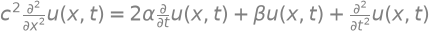

In [3]:
import sympy as sp
sp.init_printing()

# Define as variáveis independentes, os parâmetros e a função desconhecida.
x, t = sp.symbols('x, t', real=True)
c, alpha = sp.symbols('c, alpha', positive=True, real=True)
beta = sp.symbols('beta', nonnegative=True, real=True)
u = sp.Function('u')(x, t)

# Registra simbolicamente a equação do telégrafo.
eq_telegrafo = sp.Eq(
    c**2 * sp.Derivative(u, x, 2),
    sp.Derivative(u, t, 2) + 2*alpha*sp.Derivative(u, t) + beta*u
)
eq_telegrafo

## **Separação de variáveis**

Supomos uma solução separável da forma

$$u(x,t)=X(x)T(t).$$

Substituindo na equação do telégrafo e dividindo por $c^2X(x)T(t)$, obtemos

\begin{align}
c^2\frac{\partial^2(XT)}{\partial x^2}&=\frac{\partial^2(XT)}{\partial t^2}+2\alpha\frac{\partial(XT)}{\partial t}+\beta(XT)\\
\implies c^2X''T&=XT''+2\alpha XT'+\beta XT\\
\implies \frac{X''}{X}&=\frac{1}{c^2}\frac{T''+2\alpha T'+\beta T}{T}.
\end{align}

A chamada `sp.pde_separate` verifica simbolicamente essa separação, seguindo o mesmo procedimento computacional usado nos notebooks de Laplace, calor e onda.

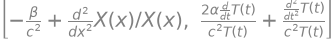

In [4]:
# Define fatores espaciais e temporais para a separação de variáveis.
X = sp.Function('X')(x)
T = sp.Function('T')(t)

# Verifica simbolicamente a separação multiplicativa da solução.
sp.pde_separate(eq_telegrafo, u, [X, T], strategy='mul')

## **Equações separadas e condições**

Como os lados da igualdade dependem de variáveis diferentes, igualamos ambos à constante $-\lambda$. Assim, obtemos as EDOs

$$\frac{X''}{X}=-\lambda,\qquad \frac{T''+2\alpha T'+\beta T}{c^2T}=-\lambda.$$

As condições de contorno implicam $X(0)=X(L)=0$. A condição de velocidade inicial implica $T'(0)=0$, considerando soluções não identicamente nulas.

Começamos pela EDO espacial com uma das condições de contorno:

$$X''=-\lambda X,\qquad X(0)=0.$$

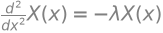

In [5]:
# Define a EDO espacial associada à constante de separação lambda.
Lambda = sp.symbols('lambda', positive=True, real=True)
edo_X = sp.Eq(sp.Derivative(X, x, 2), -Lambda * X)
edo_X

## **Resolução da EDO espacial**

Resolvemos simbolicamente a EDO para $X$, impondo a condição $X(0)=0$.

In [6]:
# Resolve a EDO espacial impondo a condição de contorno X(0) = 0.
sp.dsolve(edo_X, X, ics={X.subs(x, 0): 0})

## **Autovalores e autofunções espaciais**

A condição $X(0)=0$ fornece uma solução proporcional a $\sin(\sqrt{\lambda}x)$. Impomos agora a outra condição de contorno, $X(L)=0$:

\begin{align}
\sin(\sqrt{\lambda}L)&=0.
\end{align}

Essa condição determina os autovalores admissíveis.

In [7]:
# Define a condição X(L) = 0 para determinar os autovalores.
L = sp.symbols('L', positive=True)
eq_lambda = sp.Eq(sp.sin(sp.sqrt(Lambda) * L), 0)
eq_lambda

## **Determinação dos autovalores**

A seguir, resolvemos simbolicamente a condição $\sin(\sqrt{\lambda}L)=0$. A ferramenta retorna um representante; considerando todos os múltiplos inteiros de $\pi$, obtemos a família completa de autovalores.

In [8]:
# Resolve a condição de contorno em lambda.
sp.solve(eq_lambda, Lambda)

## **Modos espaciais e EDO temporal**

Como a função seno se anula em todos os múltiplos inteiros de $\pi$, os autovalores admissíveis são

$$\lambda_n=\left(\frac{n\pi}{L}\right)^2,\qquad n=1,2,3,\ldots$$

As autofunções espaciais correspondentes são

$$X_n(x)=\sin\left(\frac{n\pi x}{L}\right),\qquad n=1,2,3,\ldots$$

Substituindo $\lambda_n$ na equação temporal, obtemos

$$T_n''+2\alpha T_n'+\left(\beta+c^2\left(\frac{n\pi}{L}\right)^2\right)T_n=0,
\qquad T_n'(0)=0.$$

Definimos $\omega_n^2=c^2(n\pi/L)^2+\beta-\alpha^2$, de modo que o coeficiente de $T_n$ é $\omega_n^2+\alpha^2$.

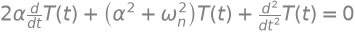

In [18]:
# Define o índice do modo e sua frequência amortecida.
n = sp.symbols('n', integer=True, positive=True)
omega_n = sp.symbols('omega_n', positive=True)

# Define a EDO temporal usando beta + c^2*(n*pi/L)^2 = omega_n^2 + alpha^2.
edo_T = sp.Eq(
    sp.Derivative(T, t, 2) + 2*alpha*sp.Derivative(T, t) + (omega_n**2 + alpha**2)*T,
    0
)
edo_T

## **Resolução da EDO temporal**

Usamos o SymPy para obter a solução da EDO temporal sujeita à condição $T_n'(0)=0$. A amplitude inicial será determinada depois pela condição $u(x,0)=f(x)$.

In [19]:
# Resolve a EDO temporal impondo a velocidade inicial T'(0) = 0.
sp.simplify(sp.dsolve(edo_T, T, ics={sp.Derivative(T, t).subs(t, 0): 0}))

## **Solução temporal e série de Fourier**

No regime oscilatório amortecido, em que $\omega_n=\sqrt{c^2(n\pi/L)^2+\beta-\alpha^2}>0$, a fórmula de Euler permite escrever a solução temporal como

$$T_n(t)=e^{-\alpha t}\left[\cos(\omega_nt)+\frac{\alpha}{\omega_n}\sin(\omega_nt)\right].$$

Com as condições de contorno homogêneas e $T_n'(0)=0$, cada modo da solução é

$$u_n(x,t)=e^{-\alpha t}\left[\cos(\omega_nt)+\frac{\alpha}{\omega_n}\sin(\omega_nt)\right]\sin\left(\frac{n\pi x}{L}\right),\qquad n=1,2,3,\ldots$$

Como a equação é linear e homogênea, combinamos os modos por superposição:

$$u(x,t)=\sum_{n=1}^{\infty}c_n e^{-\alpha t}\left[\cos(\omega_nt)+\frac{\alpha}{\omega_n}\sin(\omega_nt)\right]\sin\left(\frac{n\pi x}{L}\right).$$

Aplicando a condição inicial $u(x,0)=f(x)$, vemos que $c_n$ são os coeficientes da série de Fourier de senos de $f$ em $[0,L]$:

$$c_n=\frac{2}{L}\int_0^L f(x)\sin\left(\frac{n\pi x}{L}\right)\,dx.$$

---

# **Resolução numérica por diferenças finitas**

Nesta seção, construiremos a aproximação numérica em etapas: definiremos as malhas, aplicaremos as condições iniciais, avançaremos no tempo e compararemos o resultado com a solução analítica de um modo.

Usamos as diferenças centrais estudadas nos materiais da disciplina:

$$u_{xx}(x_i,t_j)\approx\frac{u_{i+1,j}-2u_{i,j}+u_{i-1,j}}{h_x^2},\qquad
u_{tt}(x_i,t_j)\approx\frac{u_{i,j+1}-2u_{i,j}+u_{i,j-1}}{h_t^2},$$

$$u_t(x_i,t_j)\approx\frac{u_{i,j+1}-u_{i,j-1}}{2h_t}.$$

## **Discretização do domínio**

Dividimos $[0,L]$ em $n_x$ pontos igualmente espaçados e $[0,t_{\mathrm{final}}]$ em $n_t+1$ instantes. Os passos uniformes são $h_x=x_{i+1}-x_i$ e $h_t=t_{j+1}-t_j$. Os valores numéricos abaixo são ilustrativos; o problema ainda precisa fornecer os parâmetros e o perfil inicial específicos.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Define parâmetros ilustrativos para o exemplo numérico.
L_num = 4.0
c_num = 1.0
alpha_num = 0.25
beta_num = 0.25
t_final = 2.0
n_x = 81
n_t = 400

# Constrói as malhas uniformes de espaço e tempo.
xi = np.linspace(0.0, L_num, n_x)
tj = np.linspace(0.0, t_final, n_t + 1)
h_x = xi[1] - xi[0]
h_t = tj[1] - tj[0]
print(f"Passos da malha: h_x = {h_x:.5f}, h_t = {h_t:.5f}")

Passos da malha: h_x = 0.05000, h_t = 0.00500


## **Aplicação das condições iniciais**

Para demonstrar o cálculo, escolhemos $f(x)=\sin(\pi x/L)$, que satisfaz os contornos homogêneos. A velocidade inicial continua sendo $u_t(x,0)=0$.

A diferença central em $t=0$ implica $u_{i,-1}=u_{i,1}$. Substituindo essa relação e $u_{i,0}=f(x_i)$ na equação discretizada, obtemos o primeiro nível temporal:

$$u_{i,1}=f(x_i)+\frac{h_t^2}{2}\left(c^2\frac{f(x_{i+1})-2f(x_i)+f(x_{i-1})}{h_x^2}-\beta f(x_i)\right).$$

In [3]:
# Define o perfil inicial usado no exemplo.
f_num = lambda x_val: np.sin(np.pi * x_val / L_num)

# Inicializa a solução com zero, incluindo as extremidades fixas.
u_num = np.zeros((n_x, n_t + 1))
u_num[1:-1, 0] = f_num(xi[1:-1])

# Calcula o segundo nível temporal usando u_t(x, 0) = 0.
f_xx = (u_num[2:, 0] - 2.0 * u_num[1:-1, 0] + u_num[:-2, 0]) / h_x**2
u_num[1:-1, 1] = u_num[1:-1, 0] + (h_t**2 / 2.0) * (
    c_num**2 * f_xx - beta_num * u_num[1:-1, 0]
)

## **Recorrência no tempo**

Substituindo as três aproximações centrais na equação do telégrafo e isolando $u_{i,j+1}$, obtemos

$$u_{i,j+1}=\frac{\left(\frac{c h_t}{h_x}\right)^2(u_{i+1,j}-2u_{i,j}+u_{i-1,j})+(2-\beta h_t^2)u_{i,j}-(1-\alpha h_t)u_{i,j-1}}{1+\alpha h_t}.$$

Aplicamos essa fórmula aos pontos interiores; nas extremidades, mantemos os valores nulos. Esta recorrência é uma dedução algébrica das diferenças finitas do material, não uma fórmula pronta para o telégrafo.

In [4]:
# Calcula a razão entre os passos que aparece na recorrência.
razao_espaco_tempo = (c_num * h_t / h_x)**2

# Avança a solução no tempo sem alterar os pontos de contorno.
for j in range(1, n_t):
    diferenca_espacial = (
        u_num[2:, j] - 2.0 * u_num[1:-1, j] + u_num[:-2, j]
    )
    u_num[1:-1, j + 1] = (
        razao_espaco_tempo * diferenca_espacial
        + (2.0 - beta_num * h_t**2) * u_num[1:-1, j]
        - (1.0 - alpha_num * h_t) * u_num[1:-1, j - 1]
    ) / (1.0 + alpha_num * h_t)

print(f"Razão c*h_t/h_x = {c_num * h_t / h_x:.3f}")

Razão c*h_t/h_x = 0.100


## **Comparação com a solução analítica**

Para o primeiro modo, a frequência satisfaz $\omega_1^2=c^2(\pi/L)^2+\beta-\alpha^2$. Avaliamos a solução analítica nos mesmos pontos $(x_i,t_j)$ e calculamos o erro médio absoluto, métrica de comparação utilizada nas atividades de aproximação numérica da disciplina.

In [5]:
# Confirma que os parâmetros escolhidos produzem um modo oscilatório.
omega_quadrado = c_num**2 * (np.pi / L_num)**2 + beta_num - alpha_num**2
if omega_quadrado <= 0:
    raise ValueError("Os parâmetros escolhidos não estão no regime oscilatório.")
omega_num = np.sqrt(omega_quadrado)

# Avalia a solução analítica na mesma malha espaço-tempo.
XX, TT = np.meshgrid(xi, tj, indexing="ij")
U_exata = (
    np.exp(-alpha_num * TT)
    * (np.cos(omega_num * TT) + alpha_num / omega_num * np.sin(omega_num * TT))
    * np.sin(np.pi * XX / L_num)
)

# Calcula o erro médio absoluto entre as soluções na mesma malha.
erro_medio_absoluto = np.mean(np.abs(u_num - U_exata))
print(f"Erro médio absoluto (analítica vs. numérica): {erro_medio_absoluto:.3e}")

Erro médio absoluto (analítica vs. numérica): 1.780e-05


## **Visualização da solução**

O primeiro gráfico compara as soluções analítica e numérica no tempo final. O segundo apresenta a evolução da aproximação numérica em todo o domínio espaço-tempo.

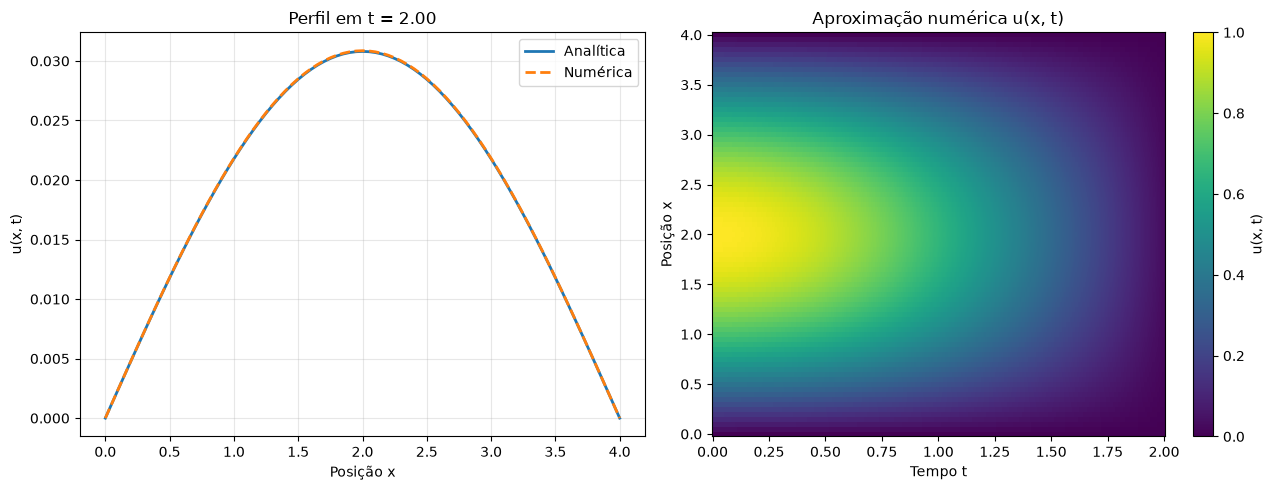

In [6]:
# Compara os perfis no instante final.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(xi, U_exata[:, -1], label="Analítica", linewidth=2)
axes[0].plot(xi, u_num[:, -1], "--", label="Numérica", linewidth=2)
axes[0].set_title(f"Perfil em t = {tj[-1]:.2f}")
axes[0].set_xlabel("Posição x")
axes[0].set_ylabel("u(x, t)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Mostra a solução aproximada em todo o domínio espaço-tempo.
imagem = axes[1].pcolormesh(tj, xi, u_num, shading="auto", cmap="viridis")
axes[1].set_title("Aproximação numérica u(x, t)")
axes[1].set_xlabel("Tempo t")
axes[1].set_ylabel("Posição x")
fig.colorbar(imagem, ax=axes[1], label="u(x, t)")
fig.tight_layout()
plt.show()

## **Verificação do conteúdo e da notação**

### **Fórmulas específicas da equação do telégrafo**

A equação do telégrafo e sua EDO temporal amortecida não aparecem literalmente nos notebooks do curso. A solução analítica modal, o primeiro passo temporal e a recorrência numérica deste arquivo foram derivados aplicando separação de variáveis, resolução de EDOs, séries de Fourier e diferenças finitas ensinadas pelo professor. Portanto, os métodos-base estão nos materiais, mas os resultados específicos do telégrafo são adaptações algébricas, não transcrições de fórmulas prontas.

O limite $c h_t/h_x\leq1$ dos materiais é apresentado para a equação da onda sem amortecimento e não é usado aqui como prova de estabilidade para o telégrafo. Os parâmetros e o perfil numérico são exemplos e devem ser substituídos pelos dados do problema.